# Information Gain Analysis

This notebook calculates information gain (KL divergence) for sediment rate predictions by comparing the original prediction distribution with perturbed distributions. The analysis helps identify regions where the model predictions are most sensitive to input variations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
from pathlib import Path
from scipy.stats import norm, entropy
import cmcrameri.cm as cmc
import sys
import warnings

# Suppress warnings
warnings.filterwarnings('ignore')

# Get project root and add to path
project_root = Path().resolve().parents[0] if Path().resolve().name == 'notebooks' else Path().resolve()
if project_root.name != 'mtl-mar':
    project_root = project_root.parent
sys.path.insert(0, str(project_root / "src"))
from postprocessing.visualize_prediction_map import VisualiseMap

## Load Area Calculation Data

Load latitude data to calculate cell areas for global sediment budget calculations.

In [2]:
# Load latitude data for area calculations
restrepo_features_path = project_root / "data" / "raw" / "features" / "FeaturesPhrampusLee_TOCSedRate_updated" / "GL_LATITUDE_DD.5m.nc"
rootgrp = xr.open_dataset(restrepo_features_path, format='NETCDF4')
dataset = rootgrp.variables['data']

# Calculate cell area in km² (5 arc-minute grid)
# Cell size: 9.297 km at equator
area = 9.297**2 * np.cos(dataset / 180 * np.pi)  # in km²

FileNotFoundError: [Errno 2] No such file or directory: b'/gxfs_work/cau/sunms498/work/mtl-mar/data/raw/features/FeaturesPhrampusLee_TOCSedRate_updated/GL_LATITUDE_DD.5m.nc'

## Load Prediction Distributions

Load prediction distributions for both Continental Shelf (CS) and Deep Ocean (DO) regions, then combine them into a unified global map.

In [ ]:
# Load prediction distributions
data_path = project_root / "data" / "output" / "predictionmaps_SedRate"
prediction_dist_CS = np.load(data_path / "prediction_map_dist_entire.npy")
prediction_dist_DO = np.load(data_path / "prediction_map_dist_entire.npy")

# Load masks
dataset_mask = np.load(project_root / "data" / "interim" / "masks" / "mask_deepocean.npy")
dataset_mask = np.rot90(np.rot90(np.fliplr(dataset_mask)))

land_file = project_root.parent / "nn4sedratetoc" / "data" / "raw" / "island_map.npy"
land_map = np.load(land_file)
land_map[np.isnan(land_map)] = 1

# Transform coordinate systems to match
prediction_dist_DO = np.flip(prediction_dist_DO, axis=2)
prediction_dist_CS = np.flip(prediction_dist_CS, axis=2)
prediction_dist_DO = np.rot90(prediction_dist_DO, k=2, axes=(1, 2))
prediction_dist_CS = np.rot90(prediction_dist_CS, k=2, axes=(1, 2))

# Combine CS and DO predictions
prediction_dist_overlapped = np.copy(prediction_dist_DO)
for i in range(prediction_dist_CS.shape[0]):
    # Use CS predictions where DO mask is NaN (continental shelf regions)
    prediction_dist_overlapped[i, :, :][np.isnan(dataset_mask)] = prediction_dist_CS[i, :, :][np.isnan(dataset_mask)]

# Apply land mask
for i in range(prediction_dist_overlapped.shape[0]):
    prediction_dist_overlapped[i, :, :][land_map] = np.nan

print(f"Prediction distribution shape: {prediction_dist_overlapped.shape}")


0
10
20
30
40
50
60
70
80
90


(100, 2160, 4320)

In [ ]:
## Calculate Mean Predictions

Calculate the mean prediction map and separate it into Continental Shelf (CS) and Deep Ocean (DO) regions.

In [ ]:
# Calculate mean prediction
prediction_dist_overlapped_original = prediction_dist_overlapped.mean(axis=0)

# Separate into CS and DO regions
MAR = prediction_dist_overlapped_original.copy()
MAR_CS = np.copy(MAR)
MAR_CS[~np.isnan(dataset_mask)] = np.nan  # Keep only CS regions

MAR_DO = np.copy(MAR)
MAR_DO[np.isnan(dataset_mask)] = np.nan  # Keep only DO regions

In [ ]:
## Calculate Global Sediment Budget

Calculate the global sediment budget in petagrams (Pg) for the entire ocean, and separately for Continental Shelf (CS) and Deep Ocean (DO) regions.

3.1813817856048596e+16
CS
2.3080676707775028e+16
DO
8733141148273615.0


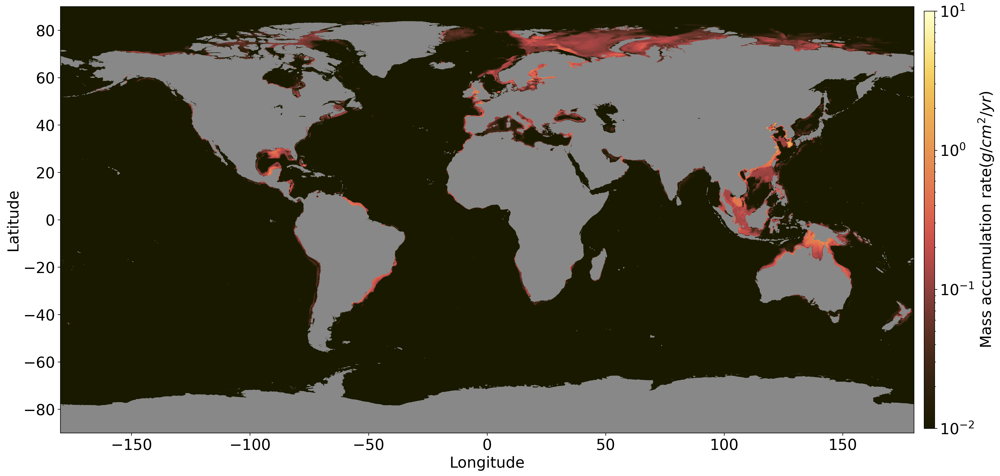

In [ ]:
# Calculate global sediment budget
# Convert km² to cm²: 1 km² = 10¹⁰ cm²
area_np = np.array(area)  # in km²

# Calculate total sediment flux (g/yr)
total_flux = np.nansum(np.multiply(MAR, area_np * 1e10)) / 1e3  # g/yr
cs_flux = np.nansum(np.multiply(MAR_CS, area_np * 1e10)) / 1e3  # g/yr
do_flux = np.nansum(np.multiply(MAR_DO, area_np * 1e10)) / 1e3  # g/yr

# Convert to petagrams (Pg/yr): 1 Pg = 10¹⁵ g
global_sed_budget_Pg = total_flux / 1e15

print(f"Global sediment budget: {global_sed_budget_Pg:.2f} Pg/yr")
print(f"Continental Shelf: {cs_flux / 1e15:.2f} Pg/yr")
print(f"Deep Ocean: {do_flux / 1e15:.2f} Pg/yr")

In [ ]:
## Visualize Global Mass Accumulation Rate

Visualize the global mass accumulation rate map.

In [ ]:
cmap = cmc.lajolla.copy()
cmap.set_bad(color='#888888')  # Gray for NaNs (land)
VisualiseMap(prediction_dist_overlapped_original / 1e3, 
             cmap=cmap, 
             use_log_norm=True, 
             vmin=1e-2, 
             vmax=1e1, 
             cbar_label="Mass accumulation rate (g/cm²/yr)")

8.918196470418978

In [ ]:
## Calculate Information Gain (KL Divergence)

Calculate information gain using KL divergence by comparing the original prediction distribution with perturbed distributions. The analysis uses region-specific uncertainty estimates (10% for deep ocean, 30% for continental shelf).

In [ ]:
# Load optimized parameters for distribution fitting
param_opt_list = np.load(project_root / "preprocessed" / "param_opt_list.npy")

'/gxfs_work/cau/sunms498/work/nn4sedratetoc/notebooks/SedRate'

'\n# Calculate PDFs for original data set\npdf_original_std = norm.pdf(prediction_dist_overlapped, param_opt_list[1], param_opt_list[2])\n# Initialize an array to store new distributions\nnew_dist = np.empty([100, prediction_dist_overlapped.shape[1], prediction_dist_overlapped.shape[2]])\n\n# Generate random normal distributions and calculate PDFs\nfor i in range(2160):\n    for j in range(4320):\n        new_dist[:,i, j] = np.random.normal(prediction_dist_overlapped.mean(axis = 0)[i, j], 0.1, 100)\n'

In [ ]:
# Calculate PDFs for original prediction distribution
pdf_original_std = norm.pdf(prediction_dist_overlapped, param_opt_list[1], param_opt_list[2])

# Calculate mean prediction
mean_prediction = prediction_dist_overlapped.mean(axis=0)
mean_prediction = np.maximum(mean_prediction, 0)

# Define region-specific uncertainty
# Deep ocean: 10% uncertainty, Continental shelf: 30% uncertainty
std_map = np.where(dataset_mask == 1, 
                   0.1 * mean_prediction,  # Deep ocean
                   0.3 * mean_prediction)  # Continental shelf

# Generate perturbed distribution with region-specific uncertainty
n_samples = 100
new_dist = np.random.normal(mean_prediction, std_map, (n_samples, 2160, 4320))

# Calculate PDFs for perturbed distribution
pdf_new_std = norm.pdf(new_dist, param_opt_list[1], 0.1)

# Calculate KL divergence (information gain)
kl_divergence_original = entropy(pdf_new_std, pdf_original_std, axis=0)

print("KL divergence calculation complete")
print(f"Shape: {kl_divergence_original.shape}")
print(f"Min: {np.nanmin(kl_divergence_original):.4f}, Max: {np.nanmax(kl_divergence_original):.4f}")


/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/stats/_entropy.py:133: RuntimeWarning: invalid value encountered in divide
  pk = 1.0*pk / np.sum(pk, axis=axis, keepdims=True)
/gxfs_home/cau/sunms498/.local/lib/python3.11/site-packages/scipy/stats/_entropy.py:139: RuntimeWarning: invalid value encountered in divide
  qk = 1.0*qk / np.sum(qk, axis=axis, keepdims=True)


nan

In [26]:
#kl_divergence_original = kl_divergence.copy()

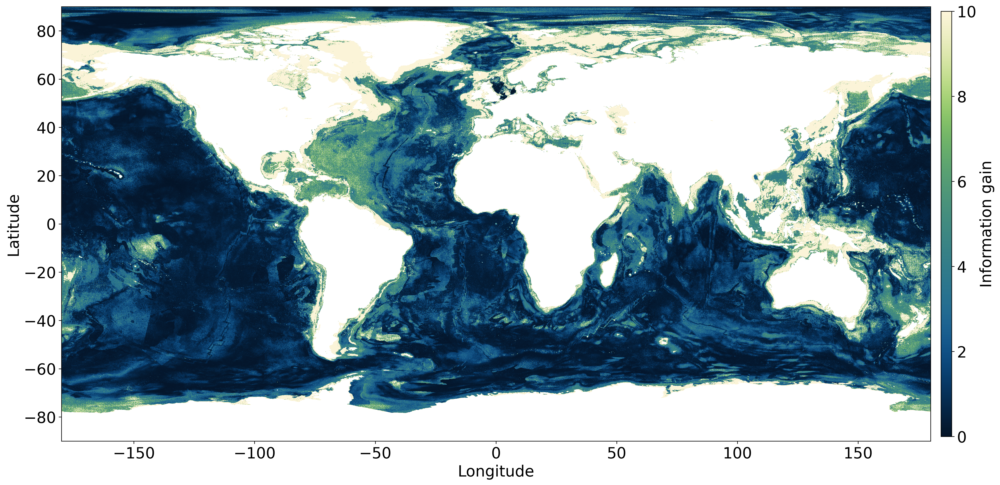

In [46]:
#kl_divergence_original_mod= np.where(kl_divergence_original == np.inf, 0, kl_divergence_original)
#kl_divergence_original_mod= np.where(kl_divergence_original_mod == np.nan, 0, kl_divergence_original_mod)
#kl_divergence_original_mod= np.where(kl_divergence_original_mod > 10, 10, kl_divergence_original_mod)
kl_divergence_original_mod = kl_divergence_original.copy()

# Mask NaN, +inf, -inf
kl_divergence_original_mod[~np.isfinite(kl_divergence_original_mod)] = np.nan
# Mask NaN, +inf, -inf
kl_divergence_original_mod[np.isnan(kl_divergence_original_mod)] = 10


# Optional: clip large finite values
kl_divergence_original_mod = np.clip(kl_divergence_original_mod, 0, 10)

# Mask land
kl_divergence_original_mod[land_map] = np.nan
#kl_divergence = np.load("kl_divergence.npy")
#kl_divergence_original_mod[:, :][land_map] = np.nan
VisualiseMap(kl_divergence_original_mod, use_log_norm=False, vmax = 10, vmin = 0, cmap=cmc.navia, cbar_label= "Information gain")#vmax = 10, vmin = 0,

In [35]:
kl_divergence_original

array([[1.50549463, 1.83204739, 3.05798855, ..., 0.6066562 , 0.72306559,
        0.64040925],
       [0.58686206, 1.19948368, 0.80869166, ..., 0.54664202, 0.32176273,
        0.39281052],
       [0.71309586, 0.5856131 , 1.16633698, ..., 0.1870197 , 0.35344835,
        0.3692987 ],
       ...,
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan],
       [       nan,        nan,        nan, ...,        nan,        nan,
               nan]])

In [23]:
np.nanmin(kl_divergence_original)

0.0

In [27]:
import numkl_divergence_original
import xarray as xr

# Define the dimensions and coordinates
lat = np.linspace(-90, 90, kl_divergence_original.shape[0])  # Latitude from -90 to 90
lon = np.linspace(-180, 180, kl_divergence_original.shape[1])  # Longitude from -180 to 180
kl_divergence = np.copy(kl_divergence_original)

# Rotate the array 180° using np.rot90
#toc_concentration = np.rot90(toc_concentration, k=2)  # Rotate 180 degrees (k=2)

# Reverse latitude and longitude coordinates to match rotated data
lat = lat[::-1]
#lon = lon[::-1]

# Create an xarray DataArray
data_array = xr.DataArray(
    data=kl_divergence,
    dims=("latitude", "longitude"),
    coords={"latitude": lat, "longitude": lon},
    name="kl_divergence"
)

# Convert to a Dataset
dataset = xr.Dataset({"kl_divergence": data_array})

# Save as a .nc file
output_path = "kl_divergence1.nc"  # Replace with your desired file path
dataset.to_netcdf(output_path)

print(f"NetCDF file saved at: {output_path}")

NetCDF file saved at: kl_divergence1.nc


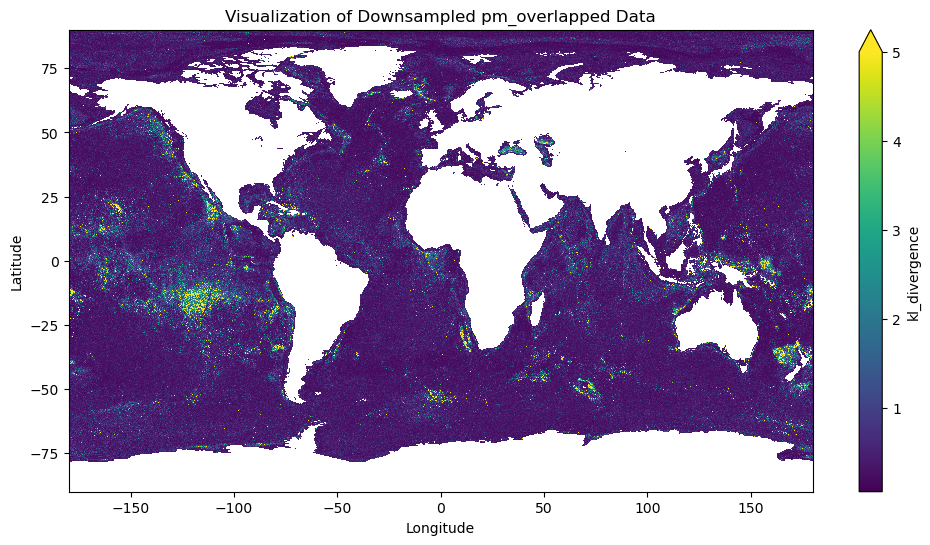

In [29]:
import matplotlib.pyplot as plt
import xarray as xr

# Load the .nc file
file_path = "kl_divergence1.nc"  # Replace with the actual file path
dataset = xr.open_dataset(file_path)

# Extract the data and downsample
data = dataset["kl_divergence"]
downsampled_data = data#[::10, ::10]  # Reduce resolution for visualization

# Plot the downsampled data
plt.figure(figsize=(12, 6))
downsampled_data.plot(cmap="viridis", vmax = 5)
plt.title("Visualization of Downsampled pm_overlapped Data")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()